# Shallow Water Waves Analysis Notebook

This notebook calculates the local short-term statistics of individual zero-crossing wave heights on shallow foreshores using the **Composite Weibull Distribution (CWD)** of Battjes and Groenendijk (2000), with Rayleigh limiting rules for weakly depth-limited conditions. It uses the same physical coefficients, branch selection, scalar CWD equations, statistical definitions, and engineering reporting as `shallow-water-waves_gui.cpp`.

**Instructions:** install the prerequisites, run the cells in order, then change the three inputs in Section 8. The graphical analyses use the underlying CWD or Rayleigh probability law; the separate caps on mean-high-wave statistics do not define another probability distribution.

## Prerequisites and Installation

Install NumPy, SciPy, pandas, Matplotlib, Jupyter, and IPython in the Python environment used by this notebook.

In [1]:
# Run this in a terminal, or remove the initial comment marker to install in Jupyter:
# %pip install numpy scipy pandas matplotlib notebook ipykernel

## 1. Theoretical Foundation: Beyond the Rayleigh Distribution

The statistical description of wave heights is fundamental to coastal engineering. In deep water, the distribution is well-described by the **Rayleigh distribution**. However, as waves move into shallow water, two key physical processes render the Rayleigh model invalid:

1.  **Nonlinear Shoaling**: As depth decreases, waves interact with the seabed, increasing their height and steepness. This enhances nonlinear effects, distorting the wave profile into a non-Gaussian shape with peaked crests and flat troughs.
2.  **Depth-Induced Breaking**: The water depth imposes a physical upper limit on wave height. The largest waves are forced to break, dissipating their energy. This truncates the upper tail of the wave height distribution, making extremely high waves far less probable than predicted by the unbounded Rayleigh model.

To address this, Battjes & Groenendijk (2000) proposed a model based on a more realistic physical hypothesis: the wave field on a shallow foreshore is a mixture of two distinct populations:
-   **Non-Breaking Waves**: Smaller waves whose heights are not significantly affected by the limited depth.
-   **Breaking/Broken Waves**: Larger waves whose heights are actively limited by the local depth.

### 1.1 The Composite Weibull Distribution (CWD)

The cumulative distribution function of the individual wave height $H$ has two Weibull branches (Battjes and Groenendijk, 2000):

$$
F(H)=\begin{cases}
1-\exp\left[-(H/H_1)^{k_1}\right],&0\leq H\leq H_{tr},\\
1-\exp\left[-(H/H_2)^{k_2}\right],&H>H_{tr}.
\end{cases}
$$

The empirical exponents are $k_1=2.0$ (Rayleigh-shaped lower branch) and $k_2=3.6$ (steeper upper tail). $H_1$ and $H_2$ are scale parameters, not individual breaker heights. At $H_{tr}$ the cumulative probability is continuous, although the density may have a jump because the branch exponents differ.

The normalized heights $\widetilde H=H/H_{rms}$ satisfy both the continuity and second-moment constraints. The calculator computes exceedance thresholds $H_N$ separately from the mean of the highest $1/N$ of waves, $H_{1/N}$.

### 1.2 Empirical Parameterization of Physical Variables

The **local** spectral wave height $H_{m0}$, still-water depth $d$, and foreshore slope denominator $M$ (slope $1:M$) determine the following parameters:

**Variance of surface elevation**

$$m_0=\left(\frac{H_{m0}}4\right)^2.$$

**Degree of saturation**

$$\mu=\frac{\sqrt{m_0}}d=\frac{H_{m0}}{4d}.$$

**Empirical root-mean-square individual wave height** (Battjes and Groenendijk, 2000)

$$H_{rms}=\left(2.69+3.24\,\mu\right)\sqrt{m_0}.$$

The coefficient 2.69 corresponds to a broad-banded deep-water relationship, rather than the ideal narrow-band Rayleigh relation $\sqrt{8}$. This distinction motivates the dimensional Rayleigh convergence treatment of Caires and Van Gent (2012).

**Slope and transitional height**

$$\tan\alpha=\frac1M,\qquad H_{tr}=\left(0.35+5.8\tan\alpha\right)d,$$

$$\widetilde H_{tr}=\frac{H_{tr}}{H_{rms}}.$$

The transition identifies the change between the two statistical branches; it is **not** a deterministic maximum wave height. The original CWD calibration used gently sloping laboratory foreshores, approximately $1:20$ to $1:250$; a long horizontal, constant-depth seabed is not equivalent to an arbitrarily mild slope.

## 2. Setup: Imports and Global Constants

All six characteristic highest-wave fractions use the same parameters, Rayleigh coefficients, and branch criterion as the C++ application.

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gamma, gammainc, gammaincc
from scipy.optimize import brentq
from IPython.display import display

K1, K2 = 2.0, 3.6
RAYLEIGH_SWITCH = 2.75
N_VALUES = (3, 10, 50, 100, 250, 1000)
RAYLEIGH_MEAN_FACTORS = dict(zip(N_VALUES, (
    1.001075736951740, 1.272734273369137, 1.560113379974762,
    1.668233372358517, 1.801017222497626, 1.984835590575388
)))
FLOAT_EPS = np.finfo(float).eps

# The C++ implementation uses 16-point Gauss-Legendre quadrature for finite intervals.
GL_POSITIVE_NODES = np.array((
    0.09501250983763744, 0.28160355077925891,
    0.45801677765722739, 0.61787624440264375,
    0.75540440835500303, 0.86563120238783174,
    0.94457502307323258, 0.98940093499164993
))
GL_POSITIVE_WEIGHTS = np.array((
    0.18945061045506850, 0.18260341504492359,
    0.16915651939500254, 0.14959598881657673,
    0.12462897125553387, 0.09515851168249278,
    0.06225352393864789, 0.02715245941175409
))

## 3. Core Mathematical Functions

The model uses **unnormalized** incomplete gamma functions. SciPy's `gammainc` and `gammaincc` are regularized, so they are multiplied by $\Gamma(a)$. The upper tail is evaluated directly, without subtracting nearly equal unnormalized gamma functions:

$$\gamma(a,x)=\Gamma(a)P(a,x),\qquad \Gamma(a,x)=\Gamma(a)Q(a,x).$$

For a finite interval in the upper-tail conditional mean, the C++ calculation uses a 16-point Gauss–Legendre integral to avoid cancellation:

$$\Gamma(a,l)-\Gamma(a,u)=\int_l^u v^{a-1}e^{-v}\,dv.$$

The same quadrature rule is used below.

In [3]:
def _positive(value, name):
    value = float(value)
    if not (np.isfinite(value) and value > 0):
        raise ValueError(f'{name} must be finite and strictly positive.')
    return value


def incomplete_gamma_lower(a, x):
    if not (np.isfinite(a) and a > 0 and np.isfinite(x) and x >= 0):
        raise ValueError('Invalid lower incomplete gamma arguments.')
    return float(gamma(a) * gammainc(a, x))


def incomplete_gamma_upper(a, x):
    if not (np.isfinite(a) and a > 0 and np.isfinite(x) and x >= 0):
        raise ValueError('Invalid upper incomplete gamma arguments.')
    return float(gamma(a) * gammaincc(a, x))


def gamma_interval(a, low, high):
    if not (np.isfinite(a) and a > 0 and np.isfinite(low) and 0 <= low <= high
            and np.isfinite(high)):
        raise ValueError('Invalid incomplete gamma interval.')
    if low == high:
        return 0.0
    middle, half = low + (high - low)/2.0, (high - low)/2.0
    u1 = middle - half * GL_POSITIVE_NODES
    u2 = middle + half * GL_POSITIVE_NODES
    values = (u1**(a-1)*np.exp(-u1) + u2**(a-1)*np.exp(-u2))
    return _positive(half * np.dot(GL_POSITIVE_WEIGHTS, values), 'Gamma interval')

## 4. Numerical Solution of the CWD Governing Equations

Continuity at the transitional height implies the common exponent

$$
q=\left(\frac{\widetilde H_{tr}}{\widetilde H_1}\right)^{k_1}
 =\left(\frac{\widetilde H_{tr}}{\widetilde H_2}\right)^{k_2}>0.
$$

Consequently, the two normalized scale parameters are recovered from one unknown:

$$\widetilde H_1=\widetilde H_{tr}\,q^{-1/k_1},\qquad
\widetilde H_2=\widetilde H_{tr}\,q^{-1/k_2}.$$

The normalized second moment must satisfy

$$
\widetilde H_{tr}^{\,2}\left[
q^{-2/k_1}\gamma\left(1+\frac{2}{k_1},q\right)
+q^{-2/k_2}\Gamma\left(1+\frac{2}{k_2},q\right)
\right]=1.
$$

We solve the logarithmic residual for $z=\ln q$ on a positive-parameter bracket, with a **Brent-type scalar root solver**. Both the final second-moment residual and CDF continuity residual are verified against $10^{-10}$. This is the same governing system as the original two-scale formulation, with continuity incorporated explicitly.

In [4]:
def logarithmic_moment_residual(log_q, log_t):
    q = math.exp(log_q)
    lower = math.exp(-2.0 / K1 * log_q) * incomplete_gamma_lower(1 + 2/K1, q)
    upper = math.exp(-2.0 / K2 * log_q) * incomplete_gamma_upper(1 + 2/K2, q)
    return 2.0 * log_t + math.log(_positive(lower + upper, 'Second-moment kernel'))


def solve_transition_exponent(t):
    t = _positive(t, 'Normalized transitional height')
    log_t = math.log(t)
    func = lambda z: logarithmic_moment_residual(z, log_t)
    lo, hi = -700.0, math.log(64.0)
    if not (func(lo) > 0 and func(hi) < 0):
        raise ArithmeticError('CWD scalar solution is outside the representable range.')
    root, details = brentq(func, lo, hi, xtol=2e-14,
                           rtol=4*FLOAT_EPS, maxiter=200, full_output=True)
    if not details.converged or abs(func(root)) > 1e-10:
        raise ArithmeticError('CWD scalar solver did not converge.')
    return _positive(math.exp(root), 'Transition exponent'), details.iterations


def solve_system(t):
    """Convenience interface returning the CWD normalized scales."""
    q, _ = solve_transition_exponent(t)
    return t * q**(-1/K1), t * q**(-1/K2)


def second_moment(a1, a2, q):
    return (a1*a1*incomplete_gamma_lower(1 + 2/K1, q)
            + a2*a2*incomplete_gamma_upper(1 + 2/K2, q))

## 5. Calculation of Statistical Wave Heights

The exceedance **threshold** $H_N$ satisfies $\Pr(H>H_N)=1/N$. It is distinct from the conditional **mean** of the highest $1/N$ fraction, $H_{1/N}$:

$$H_{1/N}=N\int_{H_N}^{\infty}Hf(H)\,dH.$$

For the CWD, writing $L=\ln N$, $q=(\widetilde H_{tr}/\widetilde H_1)^{k_1}$,

$$\widetilde H_N=\begin{cases}
\widetilde H_1L^{1/k_1},&L<q,\\
\widetilde H_2L^{1/k_2},&L\geq q,
\end{cases}$$

$$\widetilde H_{1/N}=\begin{cases}
N\left[\widetilde H_1\int_L^q u^{1/k_1}e^{-u}\,du
+\widetilde H_2\Gamma(1+1/k_2,q)\right],&L<q,\\
N\widetilde H_2\Gamma(1+1/k_2,L),&L\geq q.
\end{cases}$$

The integral is evaluated with the finite-interval quadrature defined above. In the direct Rayleigh branch, the scale used for the wave-height probability distribution is $H_{m0}/\sqrt{2}$; it must not be confused with the empirical CWD $H_{rms}$ used for diagnostics.

In [5]:
def cwd_threshold_normalized(N, a1, a2, q):
    L = math.log(float(N))
    return a1 * L**(1/K1) if L < q else a2 * L**(1/K2)


def cwd_mean_highest_normalized(N, a1, a2, q):
    L = math.log(float(N))
    if L < q:
        tail = (a1 * gamma_interval(1 + 1/K1, L, q)
                + a2 * incomplete_gamma_upper(1 + 1/K2, q))
    else:
        tail = a2 * incomplete_gamma_upper(1 + 1/K2, L)
    return _positive(N * tail, 'Mean-high-wave height')


def calculate_HN(N, H1, H2, Htr):
    """Compatibility function for the normalized CWD exceedance threshold."""
    q = (Htr / H1)**K1
    return cwd_threshold_normalized(N, H1, H2, q)


def calculate_H1N(N, H1, H2, Htr):
    """Compatibility function for the normalized CWD highest-wave mean."""
    q = (Htr / H1)**K1
    return cwd_mean_highest_normalized(N, H1, H2, q)

## 6. Plot of Dimensionless Wave-Height Ratios

The following plot shows the **underlying** CWD mean-high-wave statistics as functions of the normalized transition height, together with the direct Rayleigh continuation selected above $\widetilde H_{tr}=2.75$. This is a distribution-shape plot (prior to the input-dependent dimensional caps); it is not a second numerical solver or an independent design calculation.

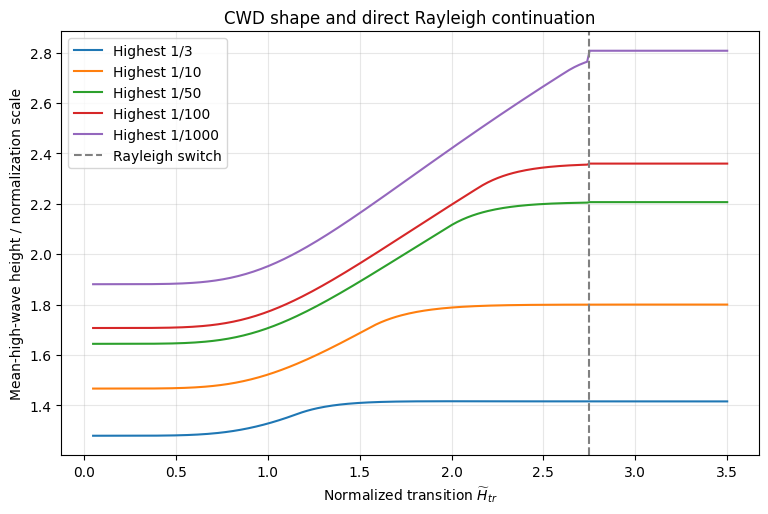

In [6]:
# Curves of unadjusted CWD statistics and the selected Rayleigh continuation.
transition_grid = np.linspace(0.05, 3.50, 250)
plot_fractions = (3, 10, 50, 100, 1000)
shape_curves = {N: [] for N in plot_fractions}
for t in transition_grid:
    if t <= RAYLEIGH_SWITCH:
        q, _ = solve_transition_exponent(float(t))
        a1, a2 = t*q**(-1/K1), t*q**(-1/K2)
        for N in plot_fractions:
            shape_curves[N].append(cwd_mean_highest_normalized(N, a1, a2, q))
    else:
        for N in plot_fractions:
            # In this normalized shape comparison, the pure Rayleigh scale is 1.
            shape_curves[N].append(N * incomplete_gamma_upper(1.5, math.log(N)))

fig, ax = plt.subplots(figsize=(9, 5.5))
for N in plot_fractions:
    ax.plot(transition_grid, shape_curves[N], label=f'Highest 1/{N}')
ax.axvline(RAYLEIGH_SWITCH, ls='--', color='gray', label='Rayleigh switch')
ax.set(xlabel=r'Normalized transition $\widetilde H_{tr}$',
       ylabel=r'Mean-high-wave height / normalization scale',
       title='CWD shape and direct Rayleigh continuation')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 7. Main Analysis Workflow

For each input case, the analysis calculates local spectral parameters, selects the CWD or Rayleigh branch, evaluates exceedance thresholds and highest-wave means, and applies separate Rayleigh upper limits to the **dimensional highest-wave means**. The final normalized highest-wave means are recalculated after any limit. Exceedance thresholds remain those of the selected underlying distribution. The result contains both tabular statistics and solver/applicability diagnostics.

In [7]:
def perform_wave_analysis(Hm0, d, slopeM):
    """Local CWD/Rayleigh statistics consistent with the native C++ calculator."""
    Hm0 = _positive(Hm0, 'Hm0')
    d = _positive(d, 'Water depth')
    slopeM = _positive(slopeM, 'Foreshore slope denominator')
    slope = _positive(1.0/slopeM, 'Foreshore slope')
    sigma = _positive(Hm0/4.0, 'Spectral standard deviation')
    m0 = _positive(sigma*sigma, 'Spectral variance')
    saturation = _positive(sigma/d, 'Degree of saturation')
    Hrms = _positive((2.69 + 3.24*saturation)*sigma, 'Hrms')
    Htr = _positive((0.35 + 5.8*slope)*d, 'Transitional height')
    t = _positive(Htr/Hrms, 'Normalized transition height')
    uses_cwd = t <= RAYLEIGH_SWITCH
    r = dict(Hm0=Hm0, d=d, depth=d, slopeM=slopeM,
             slope_denominator=slopeM, slope=slope, tanAlpha=slope,
             m0=m0, saturation=saturation, Hrms=Hrms,
             Htr=Htr, Htr_dim=Htr, Htr_tilde=t,
             transition_normalized=t, uses_cwd=uses_cwd,
             distribution_type='Composite Weibull (B&G)' if uses_cwd else 'Rayleigh',
             slope_outside_calibration=(slopeM < 20 or slopeM > 250),
             saturation_outside_observed_range=(saturation < 0.025 or saturation > 0.16),
             H1_Hrms=float('nan'), H2_Hrms=float('nan'),
             H1_dim=float('nan'), H2_dim=float('nan'),
             transition_exponent=float('nan'),
             transition_exceedance_probability=float('nan'),
             transition_recurrence_count=float('nan'),
             moment_residual=float('nan'), continuity_residual=float('nan'),
             solver_iterations=0)

    if uses_cwd:
        q, iterations = solve_transition_exponent(t)
        a1 = _positive(t*math.exp(-math.log(q)/K1), 'First Weibull scale')
        a2 = _positive(t*math.exp(-math.log(q)/K2), 'Second Weibull scale')
        moment_residual = math.sqrt(second_moment(a1, a2, q)) - 1
        continuity_residual = (t/a1)**K1 - (t/a2)**K2
        if not (math.isfinite(moment_residual) and math.isfinite(continuity_residual)
                and abs(moment_residual) <= 1e-10 and abs(continuity_residual) <= 1e-10):
            raise ArithmeticError('CWD probability constraints were not satisfied.')
        r.update(H1_Hrms=a1, H2_Hrms=a2,
                 H1_dim=a1*Hrms, H2_dim=a2*Hrms,
                 transition_exponent=q,
                 transition_exceedance_probability=math.exp(-q),
                 transition_recurrence_count=math.exp(q),
                 moment_residual=moment_residual,
                 continuity_residual=continuity_residual,
                 solver_iterations=iterations)

    stats = []
    for i, N in enumerate(N_VALUES):
        rayleigh_threshold = _positive(Hm0/math.sqrt(2.0)*math.sqrt(math.log(N)),
                                       'Rayleigh threshold')
        rayleigh_mean = _positive(RAYLEIGH_MEAN_FACTORS[N]*Hm0, 'Rayleigh mean')
        if uses_cwd:
            threshold = _positive(cwd_threshold_normalized(N, a1, a2, q)*Hrms,
                                  'CWD threshold')
            raw_mean = _positive(cwd_mean_highest_normalized(N, a1, a2, q)*Hrms,
                                 'CWD highest-wave mean')
            final_mean = min(raw_mean, rayleigh_mean)
            limited = raw_mean > rayleigh_mean*(1 + 8*FLOAT_EPS)
        else:
            threshold, raw_mean, final_mean, limited = (
                rayleigh_threshold, rayleigh_mean, rayleigh_mean, False)
        norm_mean = _positive(final_mean/Hrms, 'Normalized highest-wave mean')
        if not (raw_mean > threshold and final_mean <= rayleigh_mean*(1+1e-12)):
            raise ArithmeticError('Inconsistent wave-height statistics.')
        if stats and not (threshold > stats[-1]['threshold']
                          and raw_mean > stats[-1]['mean_unlimited']
                          and final_mean > stats[-1]['mean_final']):
            raise ArithmeticError('Wave-height ordering constraint not satisfied.')
        stat = dict(N=N, threshold=threshold, rayleigh_threshold=rayleigh_threshold,
                    mean_unlimited=raw_mean, rayleigh_mean=rayleigh_mean,
                    mean_final=final_mean, mean_normalized=norm_mean,
                    rayleigh_limit_applied=limited)
        stats.append(stat)
        # Provide fields familiar from other language implementations.
        r[f'HN_{N}_dim'] = threshold
        r[f'H1_{N}_dim'] = final_mean
        r[f'H1_{N}_Hrms'] = norm_mean
        r[f'H1_{N}_raw_dim'] = raw_mean
        r[f'H1_{N}_Rayleigh_dim'] = rayleigh_mean
        r[f'H1_{N}_limit_applied'] = limited
        if i:
            r[f'ratio_1_{N}_div_1_3'] = final_mean/stats[0]['mean_final']
    r['statistics'] = stats
    return r


def format_report(r):
    """Fixed-width UTF-8 report with the layout used by the C++ GUI/CLI."""
    lines = ['SHALLOW-WATER INDIVIDUAL WAVE-HEIGHT STATISTICS', '='*72, '',
             'INPUT PARAMETERS']

    def field(label, value, align=True):
        lines.append(f'  {label:<42} : {str(value):>16}' if align
                     else f'  {label:<42} : {value}')
    def number(value, decimals=6, scientific=False):
        return f'{value:.{decimals}{"e" if scientific else "f"}}'
    def row(frac, threshold, raw, rayleigh, final, limit):
        lines.append(f'  {frac:<10} {threshold:>11} {raw:>12} {rayleigh:>12} {final:>12} {limit:>8}')

    field('Spectral significant wave height Hm0 (m)', number(r['Hm0'],4))
    field('Still-water depth d (m)', number(r['depth'],4))
    field('Foreshore slope', '1:'+f"{r['slopeM']:.4f}".rstrip('0').rstrip('.'))
    field('tan(alpha)', number(r['slope'],6))
    lines.extend(('', 'LOCAL WAVE PARAMETERS'))
    field('Spectral variance m0 (m^2)', number(r['m0'],9,True))
    field('Individual-wave Hrms (m)', number(r['Hrms']))
    field('Degree of saturation sqrt(m0)/d', number(r['saturation']))
    field('Transitional wave height Htr (m)', number(r['Htr']))
    field('Normalized transition Htr/Hrms', number(r['transition_normalized']))
    field('Distribution',r['distribution_type'],False)
    lines.extend(('', 'DISTRIBUTION PARAMETERS'))
    if r['uses_cwd']:
        field('Normalized first Weibull scale H1/Hrms',number(r['H1_Hrms']))
        field('Normalized second Weibull scale H2/Hrms',number(r['H2_Hrms']))
        field('Dimensional Weibull scale H1 (m)',number(r['H1_dim']))
        field('Dimensional Weibull scale H2 (m)',number(r['H2_dim']))
        field('Transition exponent q',number(r['transition_exponent']))
        field('Probability P(H > Htr)',number(r['transition_exceedance_probability'],9))
        field('Equivalent transition recurrence Ntr',number(r['transition_recurrence_count'])+' waves')
    else:
        field('Composite Weibull scales H1 and H2','N/A',False)
        field('Composite Weibull transition exponent','N/A',False)
    lines.append('')
    lines.append('WAVE-HEIGHT STATISTICS (m)')
    row('HIGHEST','H_N','RAW MEAN','RAYLEIGH','FINAL MEAN','LIMIT')
    row('FRACTION','THRESHOLD','H_(1/N)','H_(1/N)','H_(1/N)','APPLIED')
    lines.append('  '+'-'*70)
    for s in r['statistics']:
        row(f"1/{s['N']}",number(s['threshold'],4),number(s['mean_unlimited'],4),
            number(s['rayleigh_mean'],4),number(s['mean_final'],4),
            'YES' if s['rayleigh_limit_applied'] else 'NO')
    lines.extend(('', 'FINAL NORMALIZED MEAN-HIGH-WAVE HEIGHTS'))
    for s in r['statistics']:
        field(f"H_(1/{s['N']}) / Hrms",number(s['mean_normalized'],7))
    lines.extend(('', 'RATIOS RELATIVE TO THE HIGHEST ONE THIRD'))
    for s in r['statistics'][1:]:
        field(f"H_(1/{s['N']}) / H_(1/3)",number(s['mean_final']/r['statistics'][0]['mean_final']))
    lines.extend(('', 'NUMERICAL DIAGNOSTICS'))
    if r['uses_cwd']:
        field('Scalar root iterations',r['solver_iterations'])
        field('Second-moment residual',number(r['moment_residual'],10,True))
        field('Continuity exponent residual',number(r['continuity_residual'],10,True))
    else:
        field('CWD nonlinear solver','N/A',False)
    lines.extend(('', 'INTERPRETATION',
        '  H_N is the height exceeded with probability 1/N.',
        '  H_(1/N) is the mean height of the highest 1/N fraction.',
        '  Both are individual-wave statistics, not storm maxima.',
        '  Mean-high-wave Rayleigh limits are applied separately.',
        '  H_N always refers to the selected underlying distribution.',
        '  The program uses local wave conditions; it does not propagate waves.'))
    if r['slope_outside_calibration'] or (r['uses_cwd'] and r['saturation_outside_observed_range']):
        lines.extend(('', 'APPLICABILITY NOTICE'))
        if r['slope_outside_calibration']:
            lines.extend((
                '  Foreshore slope is outside the laboratory slope range',
                '  1:20 to 1:250 of the Composite Weibull formulation.',
                '  Predictions for an extensive horizontal, constant-depth',
                '  seabed require a separate applicability assessment.'))
        if r['uses_cwd'] and r['saturation_outside_observed_range']:
            lines.extend((
                '  The degree of saturation is outside the approximate',
                '  interval represented by the original foreshore tests.',
                '  Interpretation requires engineering assessment.'))
    return '\n'.join(lines).rstrip('\r\n')

## 8. Execution and Results

Change the local wave conditions below and run the next cell. The CWD scales, statistical thresholds, capped highest-wave means, diagnostic ratios, and the complete fixed-width report are displayed. The report is also saved to `report.txt` in the notebook's working directory.

In [8]:
# Input parameters (metres, metres, and positive 1:M slope denominator)
Hm0_input = 2.5
d_input = 5.0
slopeM_input = 100.0

In [9]:
final_results = perform_wave_analysis(Hm0_input, d_input, slopeM_input)
report = format_report(final_results)

# No extra blank lines are written to report.txt.
with open('report.txt', 'w', encoding='utf-8', newline='\n') as handle:
    handle.write(report)

r = final_results
params = pd.DataFrame({
    'Value': [f"{r['Hm0']:.4f}", f"{r['d']:.4f}",
              f"1:{r['slopeM']:g}", f"{r['slope']:.6f}",
              f"{r['m0']:.9e}", f"{r['Hrms']:.6f}",
              f"{r['saturation']:.6f}", f"{r['Htr']:.6f}",
              f"{r['Htr_tilde']:.6f}", r['distribution_type']]
}, index=['Hm0 (m)', 'Depth (m)', 'Foreshore slope', 'tan(alpha)',
          'm0 (m²)', 'Hrms (m)', 'Degree of saturation',
          'Htr (m)', 'Htr/Hrms', 'Distribution'])
display(params)

heights = pd.DataFrame([{
    'Fraction':f"1/{s['N']}",
    'H_N threshold (m)':s['threshold'],
    'Raw mean (m)':s['mean_unlimited'],
    'Rayleigh mean (m)':s['rayleigh_mean'],
    'Final mean (m)':s['mean_final'],
    'Final / Hrms':s['mean_normalized'],
    'Rayleigh limit':'YES' if s['rayleigh_limit_applied'] else 'NO',
} for s in r['statistics']]).set_index('Fraction')
display(heights.style.format({
    c:'{:.4f}' for c in heights.select_dtypes(include='number').columns
}))

print(report)

,Value
Hm0 (m),2.5000
Depth (m),5.0000
Foreshore slope,1:100
tan(alpha),0.010000
m0 (m²),3.906250000e-01
Hrms (m),1.934375
Degree of saturation,0.125000
Htr (m),2.040000
Htr/Hrms,1.054604
Distribution,Composite Weibull (B&G)


,H_N threshold (m),Raw mean (m),Rayleigh mean (m),Final mean (m),Final / Hrms,Rayleigh limit
Fraction,,,,,,
1/3,2.2043,2.5911,2.5027,2.5027,1.2938,YES
1/10,2.7073,2.9701,3.1818,2.9701,1.5354,NO
1/50,3.1368,3.3296,3.9003,3.3296,1.7213,NO
1/100,3.2822,3.4567,4.1706,3.4567,1.7870,NO
1/250,3.4518,3.6077,4.5025,3.6077,1.8650,NO
1/1000,3.6734,3.8086,4.9621,3.8086,1.9689,NO


SHALLOW-WATER INDIVIDUAL WAVE-HEIGHT STATISTICS

INPUT PARAMETERS
  Spectral significant wave height Hm0 (m)   :           2.5000
  Still-water depth d (m)                    :           5.0000
  Foreshore slope                            :            1:100
  tan(alpha)                                 :         0.010000

LOCAL WAVE PARAMETERS
  Spectral variance m0 (m^2)                 :  3.906250000e-01
  Individual-wave Hrms (m)                   :         1.934375
  Degree of saturation sqrt(m0)/d            :         0.125000
  Transitional wave height Htr (m)           :         2.040000
  Normalized transition Htr/Hrms             :         1.054604
  Distribution                               : Composite Weibull (B&G)

DISTRIBUTION PARAMETERS
  Normalized first Weibull scale H1/Hrms     :         1.156695
  Normalized second Weibull scale H2/Hrms    :         1.110155
  Dimensional Weibull scale H1 (m)           :         2.237483
  Dimensional Weibull scale H2 (m)           : 

## 9. Graphical Analysis

The bar chart displays **final Rayleigh-limited highest-wave means**. The probability density and cumulative-distribution plots represent the **selected underlying probability law** (CWD or Rayleigh), and mark its exceedance thresholds $H_N$. The separate caps on conditional means are not an upper truncation of the probability law.

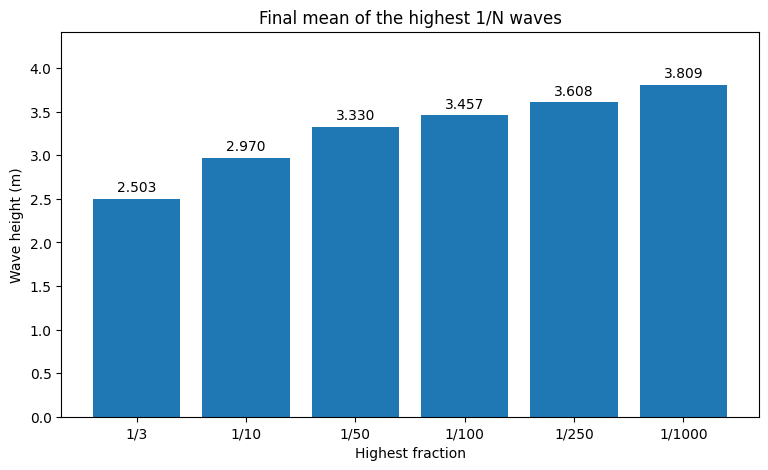

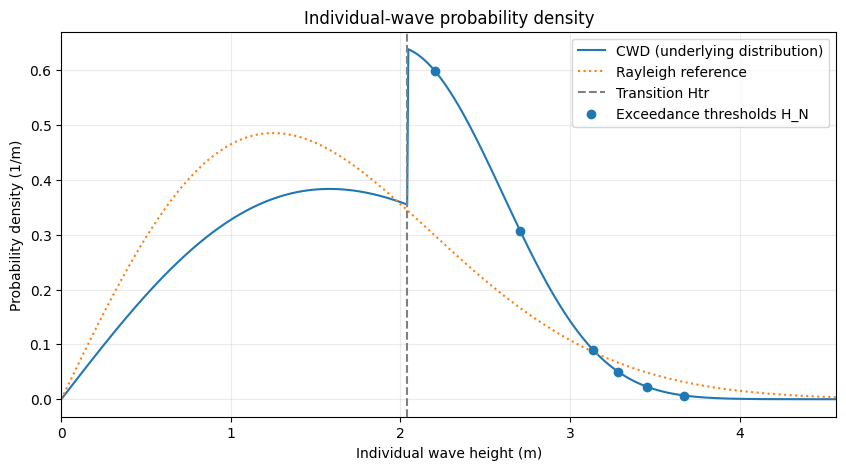

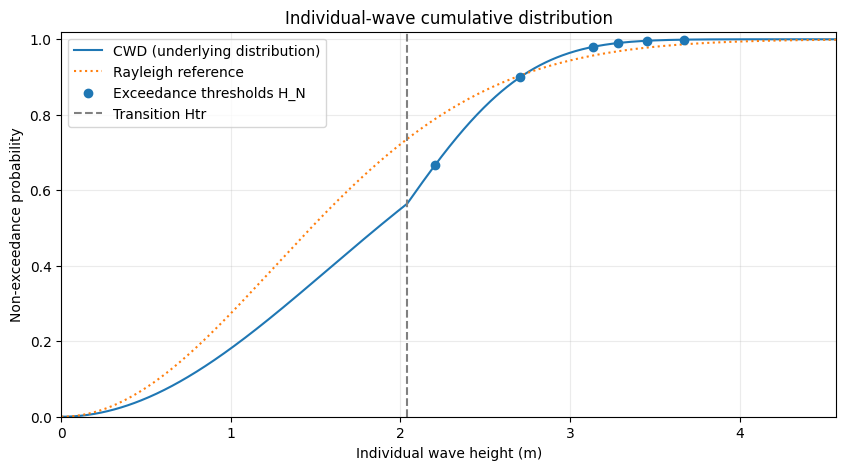

In [10]:
r = final_results
ss = r['statistics']
N = [s['N'] for s in ss]
final_means = [s['mean_final'] for s in ss]
thresholds = np.array([s['threshold'] for s in ss])

# Final conditional means.
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([f'1/{n}' for n in N], final_means)
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(title='Final mean of the highest 1/N waves', xlabel='Highest fraction',
       ylabel='Wave height (m)')
ax.set_ylim(0, max(final_means)*1.16)
plt.show()

# Underlying wave-height distribution and its exceedance thresholds.
rayleigh_scale = r['Hm0']/np.sqrt(2.0)
limit = 1.2*max(max(final_means), max(thresholds), r['Htr'] if r['uses_cwd'] else 0)
h = np.linspace(0, limit, 700)

def rayleigh_pdf(h, scale):
    return 2*h/scale**2 * np.exp(-(h/scale)**2)

def rayleigh_cdf(h, scale):
    return 1-np.exp(-(h/scale)**2)

def cwd_pdf(h, h1, h2, transition):
    h = np.asarray(h)
    return np.where(h <= transition,
                    K1/h1*(h/h1)**(K1-1)*np.exp(-(h/h1)**K1),
                    K2/h2*(h/h2)**(K2-1)*np.exp(-(h/h2)**K2))

def cwd_cdf(h, h1, h2, transition):
    h = np.asarray(h)
    return np.where(h <= transition,
                    1-np.exp(-(h/h1)**K1),
                    1-np.exp(-(h/h2)**K2))

if r['uses_cwd']:
    selected_pdf = cwd_pdf(h, r['H1_dim'], r['H2_dim'], r['Htr'])
    selected_cdf = cwd_cdf(h, r['H1_dim'], r['H2_dim'], r['Htr'])
    selected_label = 'CWD (underlying distribution)'
else:
    selected_pdf = rayleigh_pdf(h, rayleigh_scale)
    selected_cdf = rayleigh_cdf(h, rayleigh_scale)
    selected_label = 'Rayleigh (underlying distribution)'

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h, selected_pdf, label=selected_label)
ax.plot(h, rayleigh_pdf(h, rayleigh_scale), ls=':', label='Rayleigh reference')
if r['uses_cwd']:
    ax.axvline(r['Htr'], ls='--', color='gray', label='Transition Htr')
ax.scatter(thresholds, np.interp(thresholds, h, selected_pdf), zorder=4,
           label='Exceedance thresholds H_N')
ax.set(title='Individual-wave probability density',xlabel='Individual wave height (m)',
       ylabel='Probability density (1/m)', xlim=(0,limit))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h, selected_cdf, label=selected_label)
ax.plot(h, rayleigh_cdf(h, rayleigh_scale), ls=':', label='Rayleigh reference')
ax.scatter(thresholds, [1-1/n for n in N], zorder=4,
           label='Exceedance thresholds H_N')
if r['uses_cwd']:
    ax.axvline(r['Htr'], ls='--', color='gray', label='Transition Htr')
ax.set(title='Individual-wave cumulative distribution',xlabel='Individual wave height (m)',
       ylabel='Non-exceedance probability',ylim=(0,1.02),xlim=(0,limit))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 10. Bibliography

- **Battjes, J. A., & Groenendijk, H. W. (2000).** Wave height distributions on shallow foreshores. *Coastal Engineering*, 40(3), 161-182.
- **Caires, S., & Van Gent, M. R. A. (2012).** Wave height distribution in constant and finite depths. *Coastal Engineering Proceedings*, 1(33), 15.
- **Goda, Y. (1979).** A review on statistical interpretation of wave data. *Report of the Port and Harbour Research Institute, Japan*, 18(1), 5-32.
- **Groenendijk, H. W. (1998).** *Shallow foreshore wave height statistics*. M.Sc.-thesis, Delft University of Technology, Department of Civil Engineering, Section Fluid Mechanics, The Netherlands.
- **Groenendijk, H. W., & Van Gent, M. R. A. (1998).** *Shallow foreshore wave height statistics; A predictive model for the probability of exceedance of wave heights*. Technical Report H3351, WL | delft hydraulics, The Netherlands.
- **Hasselmann, K., Barnett, T. P., Bouws, E., Carlson, H., Cartwright, D. D. E., Enke, K.,... & Walden, H. (1973).** *Measurements of Wind-Wave Growth and Swell Decay during the Joint North Sea Wave Project (JONSWAP)*. Ergnzungsheft zur Deutschen Hydrographischen Zeitschrift Reihe, A (8), 95.
- **James, J. P., & Panchang, V. (2022).** Investigation of Wave Height Distributions and Characteristic Wave Periods in Coastal Environments. *Journal of Geophysical Research: Oceans*, 127, e2021JC018144.
- **Karmpadakis, I., Swan, C., & Christou, M. (2020).** Assessment of wave height distributions using an extensive field database. *Coastal Engineering*, 157, 103630.
- **Karmpadakis, I., Swan, C., & Christou, M. (2022).** A new wave height distribution for intermediate and shallow water depths. *Coastal Engineering*, 175, 104130.
- **Klopman, G. (1996).** *Extreme wave heights in shallow water*. WL | delft hydraulics, Report H2486, The Netherlands.
- **Klopman, G., & Stive, M. J. F. (1989).** *Extreme waves and wave loading in shallow water*. Paper presented at the E&P Forum Workshop in Paris, Delft Hydraulics, The Netherlands.
- **Longuet-Higgins, M. S. (1952).** On the statistical distribution of heights of sea waves. *Journal of Marine Research*, 11(3), 245-266.
- **Longuet-Higgins, M. S. (1980).** On the distribution of the heights of sea waves: Some effects of nonlinearity and finite band width. *Journal of Geophysical Research*, 85(C3), 1519-1523.
- **Naess, A. (1985).** On the distribution of crest to trough wave heights. *Ocean Engineering*, 12(3), 221-234.
- **Tayfun, M. A. (1990).** Distribution of large wave heights. *Journal of Waterway, Port, Coastal, and Ocean Engineering*, 116(6), 686-707.
- **Thornton, E. B., & Guza, R. T. (1982).** Energy saturation and phase speeds measured on a natural beach. *Journal of Geophysical Research*, 87(C12), 9499-9508.
- **Thornton, E. B., & Guza, R. T. (1983).** Transformation of wave height distribution. *Journal of Geophysical Research*, 88(C10), 5925-938.